In [1]:
from ultralytics import YOLO
model= YOLO('runs/detect/train-3/weights/best.pt')

In [6]:
# 검증용(테스트용) 데이터셋으로 검증(테스트)하도록.
metrics= model.val(
    data='yolo-bolt-nut-washer-dataset/data.yaml',
    split='test',
    conf=0.5
)

#성능평가 지표들 확인(정밀도, 재현율. mAP)
print(metrics.box.mp)  #정밀도(precision) : 검출했다고 판단한 것 중 실제 정답인 비율
print(metrics.box.mr)  #재현율(recall)  : 실제 그 객체를 얼마나 많이 검출했느냐 비율
print(metrics.box.map50)  # mAP50 : IOU 0.5 기준 평균 검출 성능 .. 예측 박스와 실제 박스가 50%만 겹치면 올바르다고 판단하는 검출 성능지표. 대략적 검출 성능지표
print(metrics.box.map) # mAP50-95 : IOU 0.5~0.95까지 0.05단위로 총 10개의 기준값으로 성능평가하고 평균을 낸 값.

Ultralytics 8.4.208  Python-3.14.5 torch-2.11.0+cu130 CUDA:0 (NVIDIA GeForce RTX 3060 Ti, 8192MiB)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 220.9±69.5 MB/s, size: 15.8 KB)
val: Scanning C:\Users\mbc\MBCA\00_Remind\04_YOLO\04 Computer Vision\03 YOLO Custom\yolo-bolt-nut-washer-dataset\test\labels.cache... 53 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 53/53 27.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.3it/s 3.1s0.3ss
                   all         53        176      0.953      0.945      0.937      0.847
                  Bolt         20         35      0.938      0.857      0.843      0.745
                   Nut         19         55      0.932          1      0.993      0.894
                Washer         25         86      0.988      0.977      0.975      0.902
Speed: 1.5ms preprocess, 6.0ms inference,

In [3]:
#성능평가지표를 보면 볼트 검출이 가장 안좋음
#그러니, 볼트 이미지를 더 준비하여 추가학습하거나, 기존 데이터셋을 조정...하여 개선

Ultralytics 8.4.208  Python-3.14.5 torch-2.11.0+cu130 CUDA:0 (NVIDIA GeForce RTX 3060 Ti, 8192MiB)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 367.4±242.0 MB/s, size: 25.5 KB)
val: Scanning C:\Users\mbc\MBCA\00_Remind\04_YOLO\04 Computer Vision\03 YOLO Custom\yolo-bolt-nut-washer-dataset\test\labels.cache... 53 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 53/53 20.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 1.4it/s 2.9s0.3ss
                   all         53        176      0.953      0.945      0.937      0.847
                  Bolt         20         35      0.938      0.857      0.843      0.745
                   Nut         19         55      0.932          1      0.993      0.894
                Washer         25         86      0.988      0.977      0.975      0.902
Speed: 1.5ms preprocess, 4.8ms inference

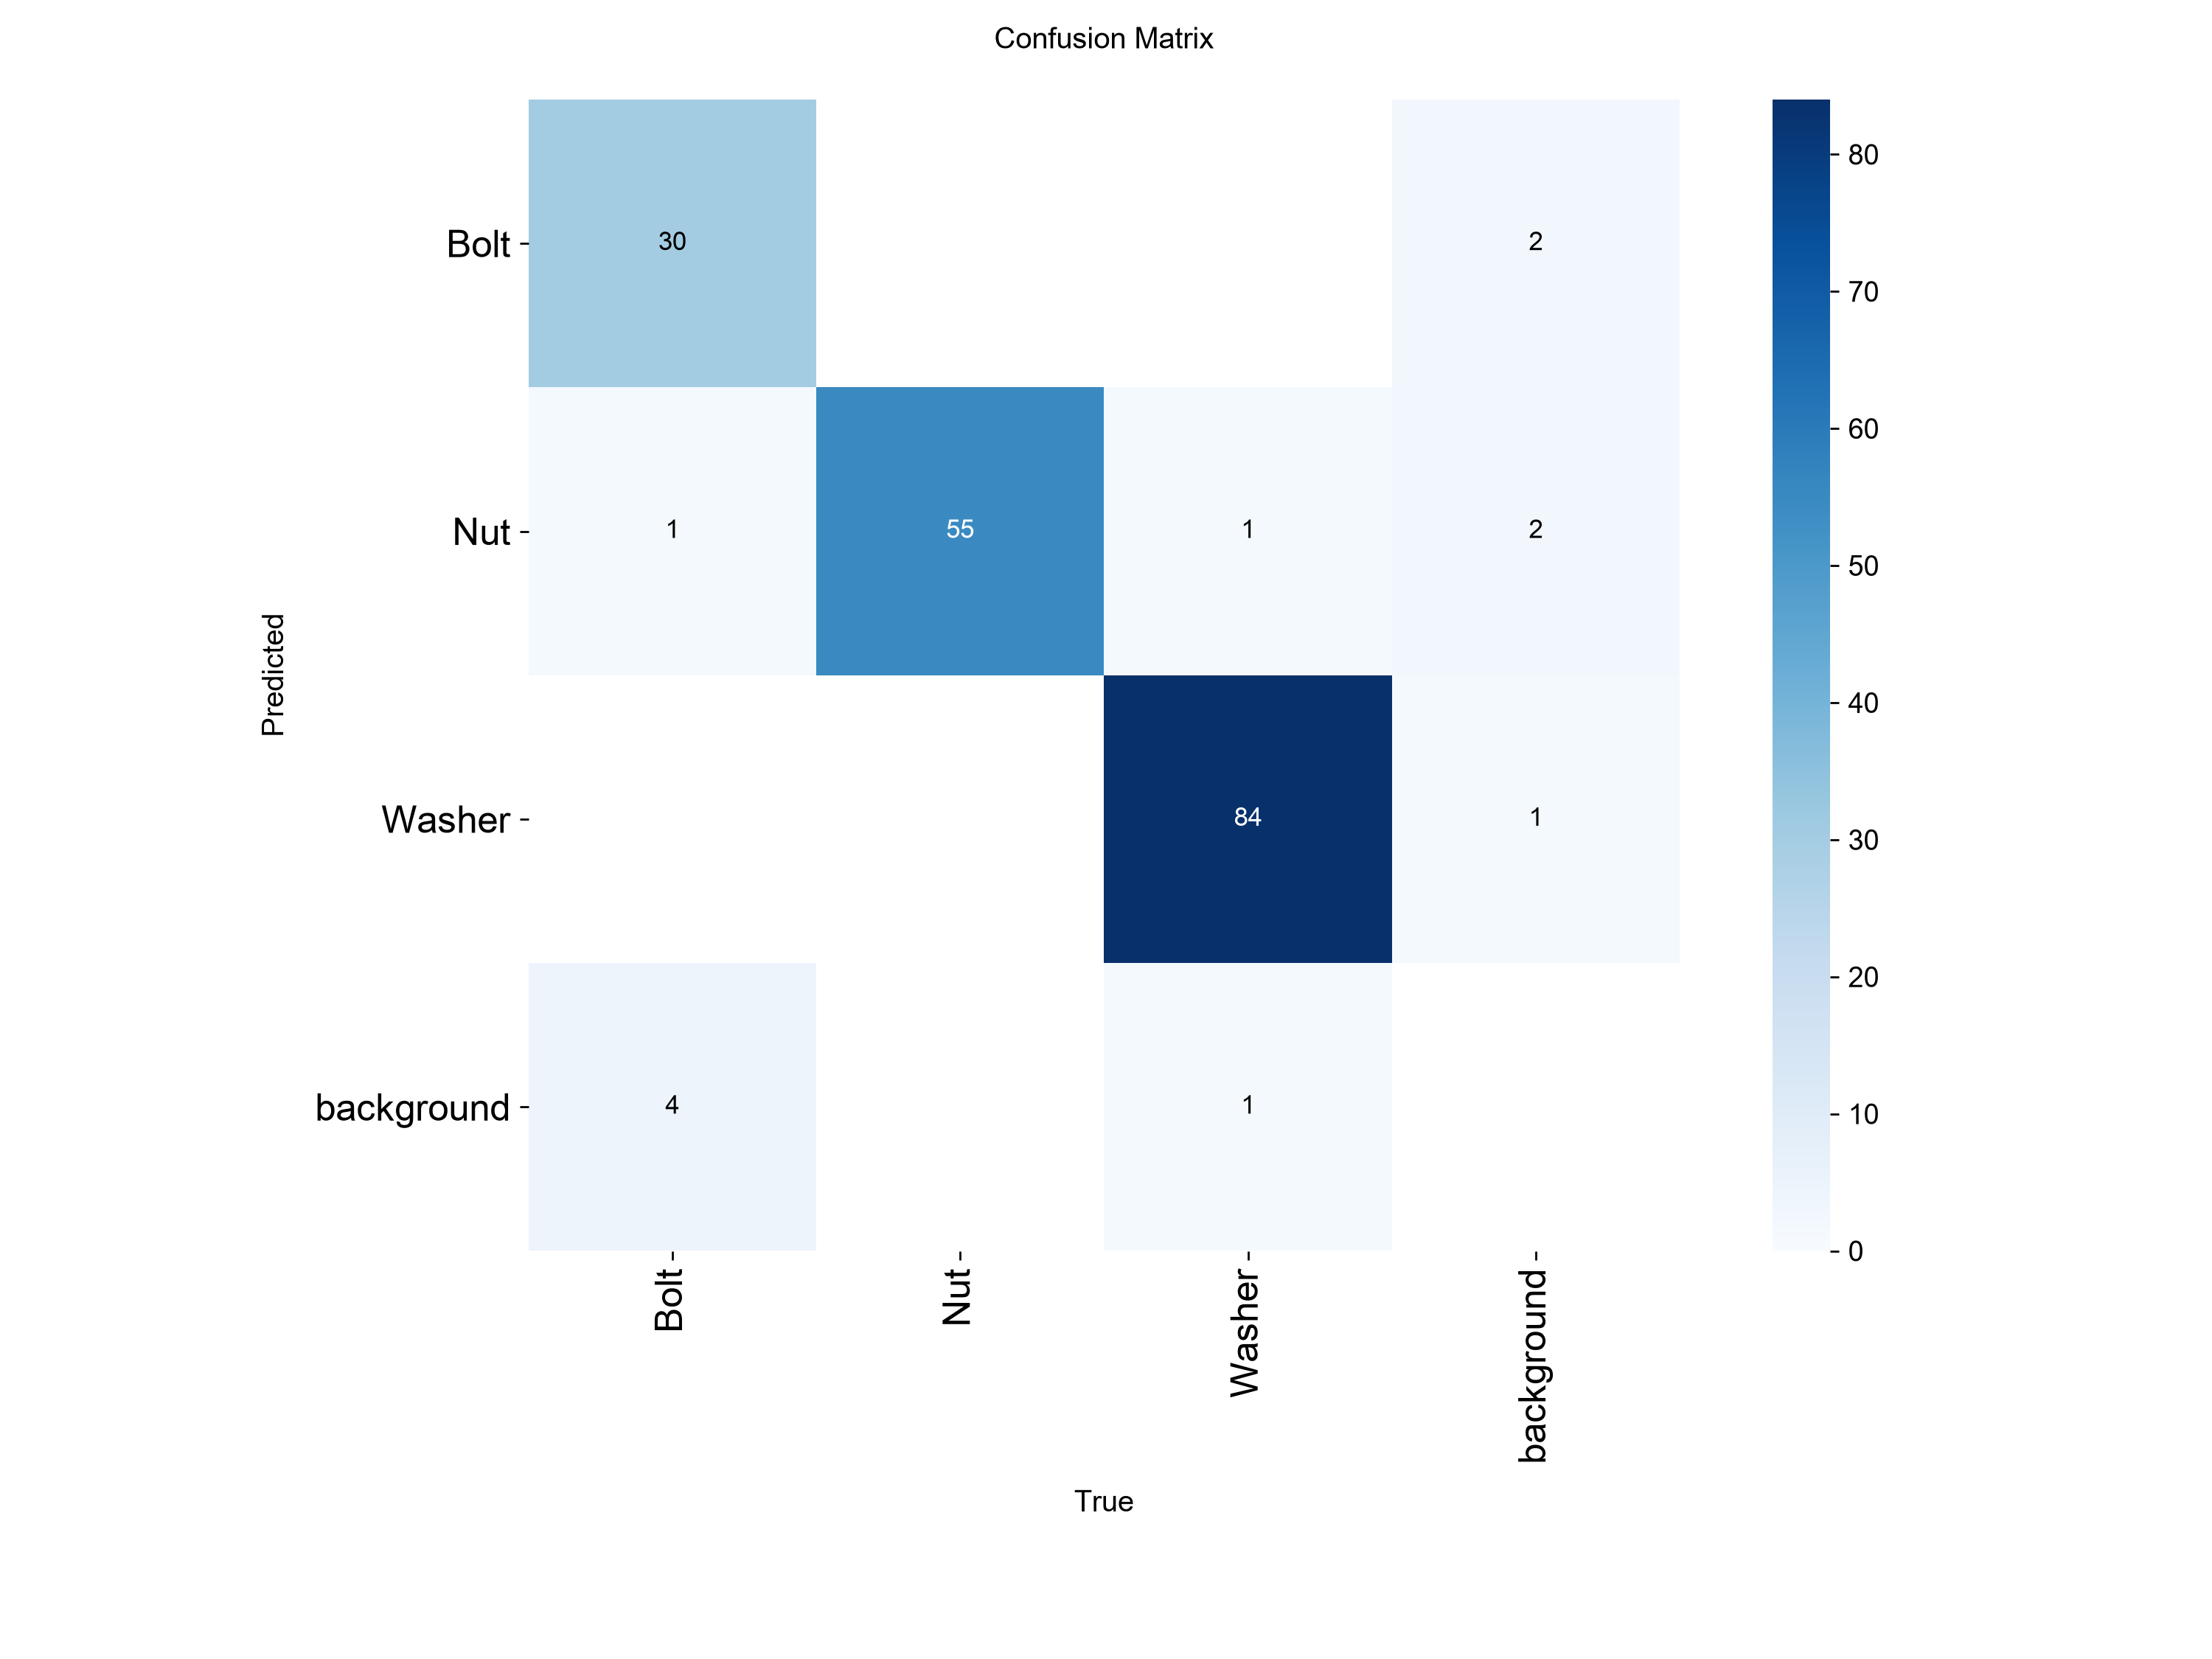

In [4]:
# 성능지표를 조금더 쉽게 보기 위해 보통 혼동행렬로 시각화 함.
metrics= model.val(
    data='yolo-bolt-nut-washer-dataset/data.yaml',
    split='test',
    conf=0.5,
    plots= True,  # 이 파라미터만 지정하면 confusion matrix가 자동 생성됨
)
from IPython.display import Image, display
from pathlib import Path
matrix_path= Path(metrics.save_dir) / 'confusion_matrix.png'
display(Image(filename=str(matrix_path)))